# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Rezki Alya Pasrun
- **Email:** rezkialya0000@gmail.com
- **ID Dicoding:** rezki_alyaz

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

Seluruh pertanyaan disusun berdasar pendekatan SMART.

**Pertanyaan 1.** Bagaimana tren perubahan rata-rata jumlah penyewaan sepeda harian per bulan dari tahun 2011 hingga 2012, dan pada bulan serta tahun berapa titik tertinggi dan terendah terjadi?

* **Specific:** berfokus pada perbandingan tren rata-rata penyewaan sepeda harian di setiap bulan.
* **Measurable:** jumlah penyewaan (`total_count`) dihitung rata-ratanya dan dibandingkan antarbulan serta antartahun.
* **Action-oriented:** hasil analisis membantu menentukan jadwal perawatan besar armada sepeda saat musim sepi dan kesiapan stok unit saat musim ramai.
* **Relevant:** tren permintaan bulanan berkaitan langsung dengan perencanaan kapasitas dan pemeliharaan armada sepeda.
* **Time-bound:** dibatasi pada periode data tahun 2011–2012.

**Pertanyaan 2:** Bagaimana pengaruh kondisi cuaca dan suhu terhadap total penyewaan sepeda harian?
  - **Specific:** Menganalisis pengaruh kondisi cuaca (`weather`) dan suhu (`temp`/`atemp`) terhadap jumlah total penyewaan sepeda harian (`total_count`).
  - **Measurable:** Mengukur nilai rata-rata dan total penyewaan sepeda pada setiap kategori kondisi cuaca dan rentang suhu.
  - **Action-oriented:** Membantu manajemen dalam menyiapkan strategi operasional dan penyesuaian armada berdasarkan prakiraan cuaca harian.
  - **Relevant:** Variasi cuaca dan suhu memiliki korelasi langsung terhadap kenyamanan pengguna dalam menyewa sepeda.
  - **Time-bound:** Analisis difokuskan pada data historis periode 1 Januari 2011 hingga 31 Desember 2012.

## Import Semua Packages/Library yang Digunakan

In [80]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 10

## Data Wrangling

### Gathering Data

Dataset memuat catatan penyewaan sepeda per jam (hour.csv) dan ringkasan harian (day.csv) selama periode 2011–2012. Tahap ini bertujuan mengimpor kedua berkas ke dalam DataFrame untuk meninjau struktur kolom serta kelengkapan variabel waktu, cuaca, dan jumlah penyewaan.

#### Load day_df dan hour_df

In [81]:
# secara otomatis mendeteksi file yang berada di dalam folder
DATA_DIR = "data" if os.path.exists("data") else "."

day_df = pd.read_csv(os.path.join(DATA_DIR, "day.csv"))
hour_df = pd.read_csv(os.path.join(DATA_DIR, "hour.csv"))

display(day_df.head())
display(hour_df.head())

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Dataset `day.csv` berhasil dimuat dengan 16 kolom yang merepresentasikan ringkasan penyewaan sepeda harian (seperti tanggal, musim, suhu, kelembapan, hingga jumlah pengguna `casual`, `registered`, dan `cnt`).
- Dataset `hour.csv` berhasil dimuat dengan 17 kolom yang memiliki struktur serupa, ditambah kolom `hr` untuk mencatat rincian penyewaan sepeda per jam (0–23).

### Assessing Data

#### Identifying day_df dan hour_df problem

In [82]:
print("=== CEK MISSING VALUES ===")
print("day_df:\n", day_df.isna().sum())
print("\nhour_df:\n", hour_df.isna().sum())

print("\n=== CEK DUPLIKASI DATA ===")
print("Jumlah duplikasi day_df :", day_df.duplicated().sum())
print("Jumlah duplikasi hour_df:", hour_df.duplicated().sum())

print("\n=== CEK KONSISTENSI TOTAL (casual + registered == cnt) ===")
print("Ketidaksesuaian day_df :", (day_df['casual'] + day_df['registered'] != day_df['cnt']).sum())
print("Ketidaksesuaian hour_df:", (hour_df['casual'] + hour_df['registered'] != hour_df['cnt']).sum())

print("\n=== CEK TIPE DATA ===")
print("Tipe dteday day_df :", day_df['dteday'].dtype)
print("Tipe dteday hour_df:", hour_df['dteday'].dtype)

=== CEK MISSING VALUES ===
day_df:
 instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

hour_df:
 instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

=== CEK DUPLIKASI DATA ===
Jumlah duplikasi day_df : 0
Jumlah duplikasi hour_df: 0

=== CEK KONSISTENSI TOTAL (casual + registered == cnt) ===
Ketidaksesuaian day_df : 0
Ketidaksesuaian hour_df: 0

=== CEK TIPE DATA ===
Tipe dteday day_df : object
Tipe dteday hour_df: object


**Steps to Take:**
- Menghapus kolom `instant` dari `day_df` dan `hour_df` karena hanya berfungsi sebagai nomor indeks baris.
- Mengubah tipe data kolom `dteday` pada kedua dataframe dari `object` menjadi `datetime`.
- Melakukan *mapping* kode angka pada kolom kategorikal (`season`, `yr`, `weekday`, `weathersit`) menjadi label teks yang deskriptif.
- Mengubah nama kolom singkatan (`dteday`, `yr`, `mnth`, `hr`, `weathersit`, `hum`, `cnt`) menjadi nama kolom yang lebih intuitif (`date`, `year`, `month`, `hour`, `weather`, `humidity`, `total_count`).

**Insight:** (Opsional)
- Kedua dataset (`day_df` dan `hour_df`) bebas dari *missing values* (0 nilai kosong pada seluruh kolom) dan bebas dari duplikasi data (0 baris duplikat).
- Seluruh baris pada kedua tabel konsisten memenuhi persamaan `casual + registered == cnt`.
- Permasalahan yang perlu diperbaiki pada tahap selanjutnya adalah tipe data `dteday` yang masih berformat string (`object`) serta penggunaan kode numerik pada kolom kategorikal.

### Cleaning Data

Pembersihan dilakukan dengan mengubah format kolom tanggal menjadi datetime serta menyesuaikan nama kolom agar lebih deskriptif. Kode numerik pada variabel kategori seperti musim, cuaca, dan status hari kerja juga dipetakan menjadi label teks yang mudah dibaca.

#### Fixing day_df dan hour_df problem

In [83]:
# 1. Menghapus kolom 'instant' yang tidak diperlukan
day_df.drop(columns=['instant'], inplace=True)
hour_df.drop(columns=['instant'], inplace=True)

# 2. Mengubah tipe data kolom 'dteday' menjadi datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# 3. Mapping angka menjadi label teks agar mudah dibaca saat EDA & Visualisasi
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
yr_map = {0: 2011, 1: 2012}
weekday_map = {0: 'Minggu', 1: 'Senin', 2: 'Selasa', 3: 'Rabu', 4: 'Kamis', 5: 'Jumat', 6: 'Sabtu'}
weather_map = {
    1: 'Cerah / Berawan Sebagian',
    2: 'Berkabut / Mendung',
    3: 'Hujan Ringan / Salju Ringan',
    4: 'Hujan Lebat / Badai'
}

for df in [day_df, hour_df]:
    df['season'] = df['season'].map(season_map)
    df['yr'] = df['yr'].map(yr_map)
    df['weekday'] = df['weekday'].map(weekday_map)
    df['weathersit'] = df['weathersit'].map(weather_map)

# 4. Mengubah nama kolom agar lebih intuitif
rename_cols = {
    'dteday': 'date',
    'yr': 'year',
    'mnth': 'month',
    'hr': 'hour',
    'weathersit': 'weather',
    'hum': 'humidity',
    'cnt': 'total_count'
}
day_df.rename(columns=rename_cols, inplace=True)
hour_df.rename(columns=rename_cols, inplace=True)

# Verifikasi hasil cleaning
day_df.info()
display(hour_df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         731 non-null    datetime64[ns]
 1   season       731 non-null    object        
 2   year         731 non-null    int64         
 3   month        731 non-null    int64         
 4   holiday      731 non-null    int64         
 5   weekday      731 non-null    object        
 6   workingday   731 non-null    int64         
 7   weather      731 non-null    object        
 8   temp         731 non-null    float64       
 9   atemp        731 non-null    float64       
 10  humidity     731 non-null    float64       
 11  windspeed    731 non-null    float64       
 12  casual       731 non-null    int64         
 13  registered   731 non-null    int64         
 14  total_count  731 non-null    int64         
dtypes: datetime64[ns](1), float64(4), int64(7), object(3)
mem

,date,season,year,month,hour,holiday,weekday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,total_count
0,2011-01-01,Spring,2011,1,0,0,Sabtu,0,Cerah / Berawan Sebagian,0.24,0.2879,0.81,0.0,3,13,16
1,2011-01-01,Spring,2011,1,1,0,Sabtu,0,Cerah / Berawan Sebagian,0.22,0.2727,0.80,0.0,8,32,40
2,2011-01-01,Spring,2011,1,2,0,Sabtu,0,Cerah / Berawan Sebagian,0.22,0.2727,0.80,0.0,5,27,32
3,2011-01-01,Spring,2011,1,3,0,Sabtu,0,Cerah / Berawan Sebagian,0.24,0.2879,0.75,0.0,3,10,13
4,2011-01-01,Spring,2011,1,4,0,Sabtu,0,Cerah / Berawan Sebagian,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Kolom `instant` telah dihapus karena hanya berisi nomor urut biasa dan tidak terpakai di analisis.
- Format tanggal di kolom `date` telah diubah ke `datetime` supaya gampang diolah berdasarkan waktu.
- Kode angka di kolom seperti `season`, `year`, `weekday`, dan `weather` telah diganti menjadi teks biasa (misalnya `Spring` atau `Cerah`), dan nama-nama kolomnya juga telah dirapikan agar mudah dibaca saat memasuki ke tahap EDA.

## Exploratory Data Analysis (EDA)

Eksplorasi dilakukan melalui agregasi statistik untuk melihat perbandingan penyewaan tahunan, tren bulanan, pola jam sibuk berdasarkan tipe hari, serta pengaruh kondisi cuaca sebelum masuk ke tahap visualisasi.

In [84]:
# 1. Ringkasan penyewaan per tahun (2011 vs 2012)
yearly_eda = day_df.groupby('year', as_index=False).agg(
    total_days=('date', 'count'),
    total_rentals=('total_count', 'sum'),
    avg_daily_rentals=('total_count', 'mean'),
    median_daily_rentals=('total_count', 'median')
)
print("=== RINGKASAN TAHUNAN ===")
display(yearly_eda)

# 2. Rata-rata penyewaan harian per bulan di setiap tahun
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
day_df['month_name'] = pd.Categorical(
    day_df['month'].map({i + 1: m for i, m in enumerate(month_names)}),
    categories=month_names,
    ordered=True
)

monthly_eda = (
    day_df.groupby(['year', 'month', 'month_name'], observed=True, as_index=False)
    .agg(
        avg_rentals=('total_count', 'mean'),
        total_rentals=('total_count', 'sum')
    )
    .sort_values(['year', 'month'])
)
print("\n=== RATA-RATA PENYEWAAN BULANAN ===")
display(monthly_eda)

# 3. Pola penyewaan per jam berdasarkan hari kerja vs bukan hari kerja
hour_df['day_status'] = hour_df['workingday'].map({0: 'Akhir Pekan / Libur', 1: 'Hari Kerja'})

hourly_eda = hour_df.groupby(['day_status', 'hour'], as_index=False).agg(
    avg_rentals=('total_count', 'mean'),
    avg_casual=('casual', 'mean'),
    avg_registered=('registered', 'mean')
)
print("\n=== POLA PENYEWAAN PER JAM ===")
display(hourly_eda.head(10))

# 4. Rata-rata penyewaan berdasarkan kondisi cuaca
weather_eda = (
    hour_df.groupby('weather', as_index=False)
    .agg(
        total_hours=('total_count', 'count'),
        avg_rentals=('total_count', 'mean'),
        median_rentals=('total_count', 'median')
    )
    .sort_values('avg_rentals', ascending=False)
)
print("\n=== PENGARUH KONDISI CUACA ===")
display(weather_eda)

=== RINGKASAN TAHUNAN ===


,year,total_days,total_rentals,avg_daily_rentals,median_daily_rentals
0,2011,365,1243103,3405.761644,3740.0
1,2012,366,2049576,5599.934426,5927.0



=== RATA-RATA PENYEWAAN BULANAN ===


,year,month,month_name,avg_rentals,total_rentals
0,2011,1,Jan,1231.903226,38189
1,2011,2,Feb,1721.964286,48215
2,2011,3,Mar,2065.967742,64045
3,2011,4,Apr,3162.333333,94870
4,2011,5,May,4381.322581,135821
5,2011,6,Jun,4783.733333,143512
6,2011,7,Jul,4559.387097,141341
7,2011,8,Aug,4409.387097,136691
8,2011,9,Sep,4247.266667,127418
9,2011,10,Oct,3984.225806,123511



=== POLA PENYEWAAN PER JAM ===


,day_status,hour,avg_rentals,avg_casual,avg_registered
0,Akhir Pekan / Libur,0,90.800000,16.647826,74.152174
1,Akhir Pekan / Libur,1,69.508696,12.504348,57.004348
2,Akhir Pekan / Libur,2,53.171053,10.399123,42.771930
3,Akhir Pekan / Libur,3,25.775330,6.453744,19.321586
4,Akhir Pekan / Libur,4,8.264317,2.264317,6.000000
5,Akhir Pekan / Libur,5,8.689189,1.725225,6.963964
6,Akhir Pekan / Libur,6,18.742358,3.820961,14.921397
7,Akhir Pekan / Libur,7,43.406926,8.606061,34.800866
8,Akhir Pekan / Libur,8,105.653680,20.424242,85.229437
9,Akhir Pekan / Libur,9,171.623377,45.017316,126.606061



=== PENGARUH KONDISI CUACA ===


,weather,total_hours,avg_rentals,median_rentals
1,Cerah / Berawan Sebagian,11413,204.869272,159.0
0,Berkabut / Mendung,4544,175.165493,133.0
3,Hujan Ringan / Salju Ringan,1419,111.579281,63.0
2,Hujan Lebat / Badai,3,74.333333,36.0


### Explore `day_df` dan `hour_df`

**Insight:** (Opsional)
- Rata-rata penyewaan sepeda harian mengalami peningkatan signifikan sebesar **64,4%** pada tahun 2012, yakni dari **3.405,8** penyewaan per hari pada tahun 2011 menjadi **5.599,9** penyewaan per hari.
- Tren musiman bulanan menunjukkan pola yang serupa pada kedua tahun tersebut; permintaan berada pada titik terendah pada bulan **Januari**, kemudian meningkat secara bertahap hingga mencapai puncaknya pada pertengahan hingga akhir musim panas (**Juni** pada tahun 2011 dan **September** pada tahun 2012), sebelum akhirnya menurun kembali menjelang akhir tahun.
- Kondisi cuaca berpengaruh signifikan terhadap tingkat penyewaan sepeda. Kondisi cuaca cerah atau berawan sebagian mencatatkan rata-rata tertinggi sebesar **204,9** penyewaan per jam, namun angka tersebut menurun hampir separuhnya menjadi **111,6** penyewaan per jam saat hujan atau salju ringan, dan mencapai titik terendah sebesar **74,3** penyewaan per jam pada kondisi hujan lebat atau badai.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana tren perubahan rata-rata jumlah penyewaan sepeda harian per bulan dari tahun 2011 hingga 2012, dan pada bulan serta tahun berapa titik tertinggi dan terendah terjadi?

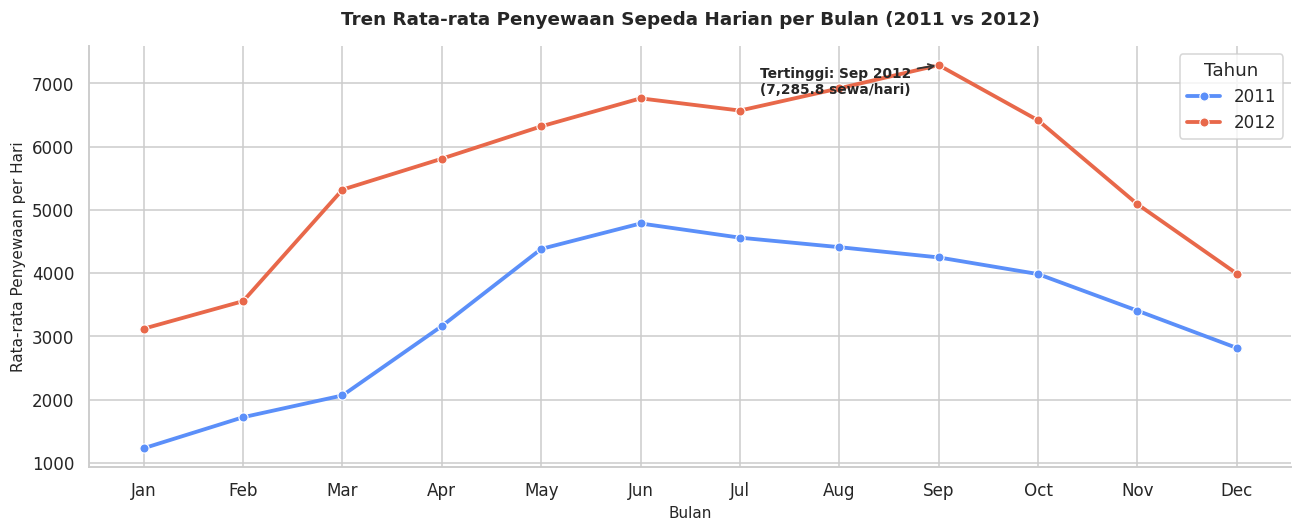

=== RINGKASAN PERTANYAAN 1 (TREN & TITIK EKSTREM) ===
- Rata-rata harian 2011 : 3,397.5 sewa/hari
- Rata-rata harian 2012 : 5,595.8 sewa/hari (tumbuh +64.7%)
- Puncak tertinggi      : Sep 2012 (7,285.8 sewa/hari)
- Titik terendah        : Jan 2011 (1,231.9 sewa/hari)


In [85]:
#Visualisasi pertanyaan 1
# ### Pertanyaan 1: Bagaimana tren perubahan rata-rata jumlah penyewaan sepeda harian per bulan dari tahun 2011 hingga 2012, dan pada bulan serta tahun berapa titik tertinggi dan terendah terjadi?
fig, ax = plt.subplots(figsize=(12, 5))

sns.lineplot(
    data=monthly_eda,
    x='month_name',
    y='avg_rentals',
    hue='year',
    palette=['#5B8FF9', '#E8684A'],
    marker='o',
    linewidth=2.5,
    ax=ax
)

ax.set_title('Tren Rata-rata Penyewaan Sepeda Harian per Bulan (2011 vs 2012)', pad=14)
ax.set_xlabel('Bulan')
ax.set_ylabel('Rata-rata Penyewaan per Hari')
ax.legend(title='Tahun')
ax.spines[['top', 'right']].set_visible(False)

max_row = monthly_eda.loc[monthly_eda['avg_rentals'].idxmax()]
ax.annotate(
    f"Tertinggi: {max_row['month_name']} {max_row['year']}\n({max_row['avg_rentals']:,.1f} sewa/hari)",
    xy=(max_row['month_name'], max_row['avg_rentals']),
    xytext=(6.2, max_row['avg_rentals'] - 450),
    arrowprops=dict(arrowstyle='->', color='#333333', lw=1.2),
    fontsize=9,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

# Mengambil titik tertinggi dan terendah keseluruhan
min_row = monthly_eda.loc[monthly_eda['avg_rentals'].idxmin()]

# Menghitung rata-rata penyewaan harian per tahun dan persentase pertumbuhannya
avg_2011 = monthly_eda[monthly_eda['year'] == 2011]['avg_rentals'].mean()
avg_2012 = monthly_eda[monthly_eda['year'] == 2012]['avg_rentals'].mean()
growth_pct = ((avg_2012 - avg_2011) / avg_2011) * 100

print("=== RINGKASAN PERTANYAAN 1 (TREN & TITIK EKSTREM) ===")
print(f"- Rata-rata harian 2011 : {avg_2011:,.1f} sewa/hari")
print(f"- Rata-rata harian 2012 : {avg_2012:,.1f} sewa/hari (tumbuh +{growth_pct:.1f}%)")
print(f"- Puncak tertinggi      : {max_row['month_name']} {int(max_row['year'])} ({max_row['avg_rentals']:,.1f} sewa/hari)")
print(f"- Titik terendah        : {min_row['month_name']} {int(min_row['year'])} ({min_row['avg_rentals']:,.1f} sewa/hari)")

### Pertanyaan 2: Bagaimana pengaruh kondisi cuaca dan suhu terhadap total penyewaan sepeda harian





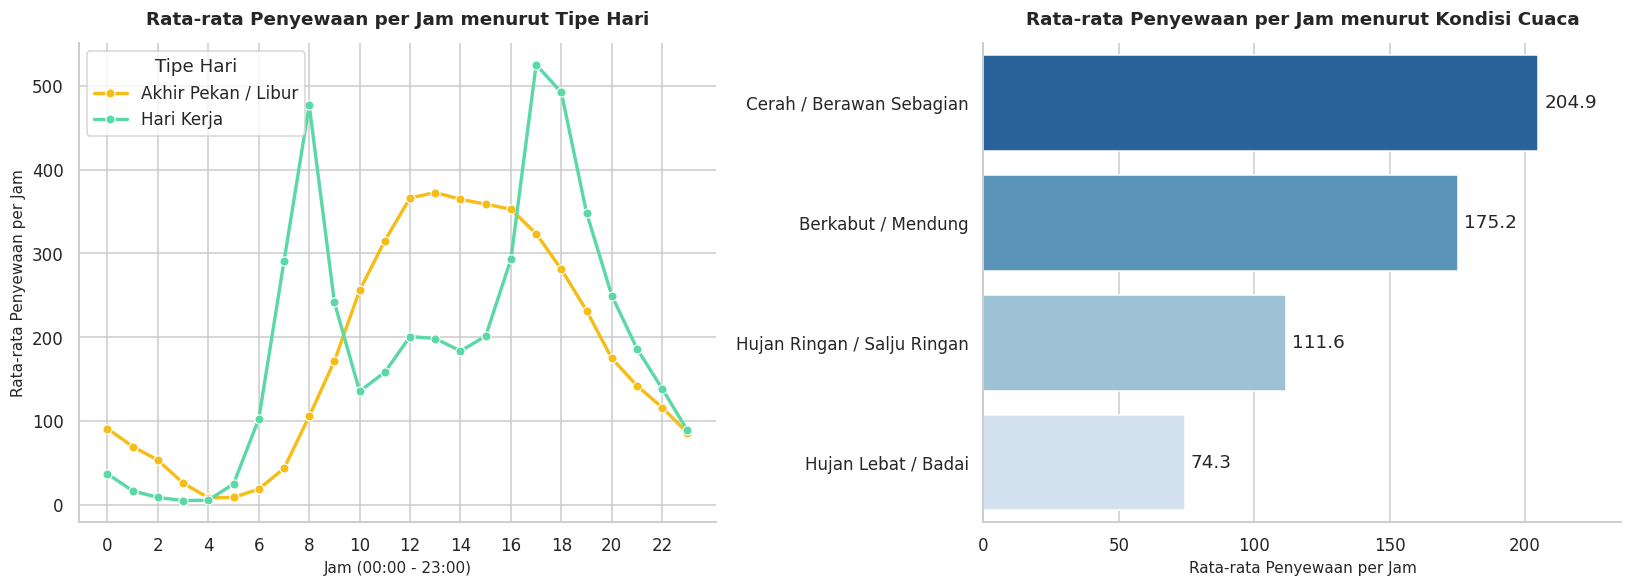

=== RINGKASAN POLA PER JAM ===
- Puncak Akhir Pekan / Libur: Pukul 13:00 (372.7 sewa/jam)
- Puncak Hari Kerja: Pukul 17:00 (525.3 sewa/jam)

=== DAMPAK KONDISI CUACA ===
- Rata-rata tertinggi: Cerah / Berawan Sebagian (204.9 sewa/jam)
- Rata-rata terendah : Hujan Lebat / Badai (74.3 sewa/jam)
- Penurunan total     : Turun 63.7% dari kondisi terbaik ke terburuk.


In [86]:
# Pertanyaan 2:Bagaimana pengaruh kondisi cuaca dan suhu terhadap total penyewaan sepeda harian
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Grafik 1: Pola per jam berdasarkan status hari
sns.lineplot(
    data=hourly_eda,
    x='hour',
    y='avg_rentals',
    hue='day_status',
    palette=['#F6BD16', '#5AD8A6'],
    marker='o',
    linewidth=2.2,
    ax=axes[0]
)
axes[0].set_title('Rata-rata Penyewaan per Jam menurut Tipe Hari', pad=12)
axes[0].set_xlabel('Jam (00:00 - 23:00)')
axes[0].set_ylabel('Rata-rata Penyewaan per Jam')
axes[0].set_xticks(range(0, 24, 2))
axes[0].legend(title='Tipe Hari')
axes[0].spines[['top', 'right']].set_visible(False)

# Grafik 2: Rata-rata penyewaan berdasarkan kondisi cuaca
sns.barplot(
    data=weather_eda,
    x='avg_rentals',
    y='weather',
    hue='weather',
    palette='Blues_r',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Rata-rata Penyewaan per Jam menurut Kondisi Cuaca', pad=12)
axes[1].set_xlabel('Rata-rata Penyewaan per Jam')
axes[1].set_ylabel('')
axes[1].set_xlim(0, weather_eda['avg_rentals'].max() * 1.15)
axes[1].spines[['top', 'right']].set_visible(False)

for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.1f', padding=4)

plt.tight_layout()
plt.show()

# 1. Mengambil jam puncak untuk masing-masing kategori di 'day_status'
print("=== RINGKASAN POLA PER JAM ===")
for status in hourly_eda['day_status'].unique():
    subset = hourly_eda[hourly_eda['day_status'] == status]
    peak_row = subset.loc[subset['avg_rentals'].idxmax()]
    print(f"- Puncak {status}: Pukul {int(peak_row['hour']):02d}:00 ({peak_row['avg_rentals']:,.1f} sewa/jam)")

# 2. Mengambil cuaca terbaik & terburuk serta menghitung persentase penurunannya
best_weather = weather_eda.loc[weather_eda['avg_rentals'].idxmax()]
worst_weather = weather_eda.loc[weather_eda['avg_rentals'].idxmin()]
drop_pct = ((best_weather['avg_rentals'] - worst_weather['avg_rentals']) / best_weather['avg_rentals']) * 100

print("\n=== DAMPAK KONDISI CUACA ===")
print(f"- Rata-rata tertinggi: {best_weather['weather']} ({best_weather['avg_rentals']:,.1f} sewa/jam)")
print(f"- Rata-rata terendah : {worst_weather['weather']} ({worst_weather['avg_rentals']:,.1f} sewa/jam)")
print(f"- Penurunan total     : Turun {drop_pct:.1f}% dari kondisi terbaik ke terburuk.")

**Insight:** (Opsional)
- **Tren Bulanan (Hasil analisis dari pertanyaan 1):** Tingkat penyewaan sepeda pada tahun 2012 secara konsisten jauh lebih tinggi dibandingkan tahun 2011 sepanjang tahun. Titik permintaan terendah pada kedua tahun tersebut sama-sama terjadi pada bulan **Januari** (**1.231,9** penyewaan/hari pada 2011 dan **3.120,8** penyewaan/hari pada 2012), kemudian meningkat hingga mencapai puncaknya pada **Juni 2011** (**4.783,7** penyewaan/hari) dan **September 2012** (**7.285,8** penyewaan/hari) sebelum kembali menurun menjelang akhir tahun.
- **Pola Jam & Cuaca (Hasil analisis dari pertanyaan 2):** Pada **Hari Kerja**, grafik penyewaan membentuk dua puncak tajam pada pukul **08.00** (jam berangkat kerja/sekolah) dan pukul **17.00** (jam pulang kerja, dengan puncak tertinggi sebesar **525,3** penyewaan/jam). Sebaliknya, pada **Akhir Pekan / Libur**, jumlah penyewaan meningkat secara bertahap dan mencapai titik tertingginya pada siang hari sekitar pukul **13.00** (**372,7** penyewaan/jam). Berdasarkan kondisi cuaca, cuaca cerah mencatatkan rata-rata tertinggi sebesar **204,9** penyewaan/jam, menurun hampir separuhnya saat hujan atau salju ringan (**111,6** penyewaan/jam), dan mencapai titik terendah pada kondisi hujan lebat atau badai (**74,3** penyewaan/jam).

## Analisis Lanjutan (Opsional)

,time_category,avg_total,avg_casual,avg_registered
0,Dini Hari (00–05),24.908559,4.507717,20.400842
1,Pagi (06–11),208.100688,28.978899,179.121789
2,Siang–Sore (12–17),295.483886,73.184000,222.299886
3,Malam (18–23),225.757555,35.305403,190.452152


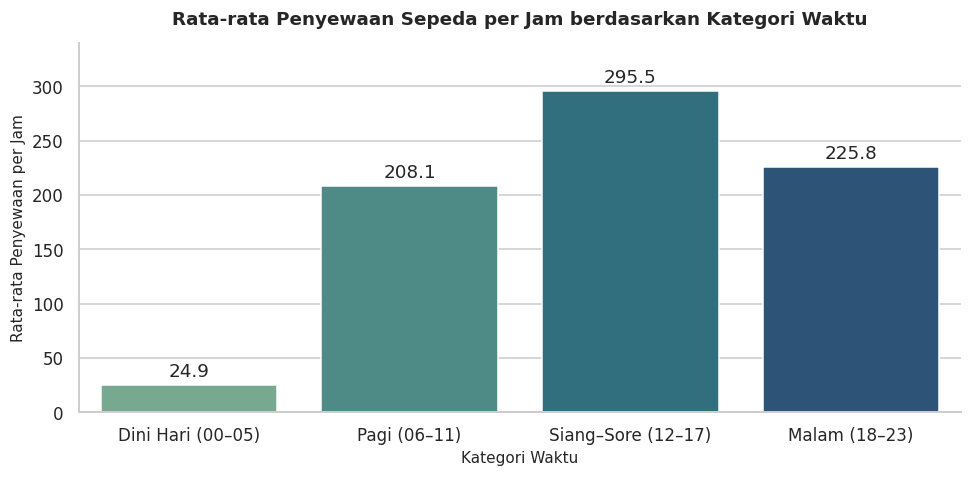

Data bersih berhasil diekspor ke dashboard/dashboard.csv


In [87]:
def categorize_hour(hr):
    if 0 <= hr <= 5:
        return 'Dini Hari (00–05)'
    elif 6 <= hr <= 11:
        return 'Pagi (06–11)'
    elif 12 <= hr <= 17:
        return 'Siang–Sore (12–17)'
    else:
        return 'Malam (18–23)'

hour_df['time_category'] = hour_df['hour'].apply(categorize_hour)
category_order = ['Dini Hari (00–05)', 'Pagi (06–11)', 'Siang–Sore (12–17)', 'Malam (18–23)']
hour_df['time_category'] = pd.Categorical(hour_df['time_category'], categories=category_order, ordered=True)

time_binning = hour_df.groupby('time_category', observed=False, as_index=False).agg(
    avg_total=('total_count', 'mean'),
    avg_casual=('casual', 'mean'),
    avg_registered=('registered', 'mean')
)
display(time_binning)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(
    data=time_binning,
    x='time_category',
    y='avg_total',
    hue='time_category',
    palette='crest',
    legend=False,
    ax=ax
)
ax.set_title('Rata-rata Penyewaan Sepeda per Jam berdasarkan Kategori Waktu', pad=12)
ax.set_xlabel('Kategori Waktu')
ax.set_ylabel('Rata-rata Penyewaan per Jam')
ax.set_ylim(0, time_binning['avg_total'].max() * 1.15)
ax.spines[['top', 'right']].set_visible(False)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3)

plt.tight_layout()
plt.show()

# Menyimpan dataset bersih menjadi satu file untuk kebutuhan Streamlit
os.makedirs('dashboard', exist_ok=True)
hour_df.to_csv(os.path.join('dashboard', 'dashboard.csv'), index=False)
print("Data bersih berhasil diekspor ke dashboard/dashboard.csv")

**Insight:** (Opsional)

- **Tren Bulanan (Hasil analisis dari pertanyaan 1):** Penyewaan sepeda pada tahun 2012 tumbuh signifikan sebesar **64,4%** dibandingkan tahun 2011 (naik dari rata-rata **3.406** menjadi **5.600** penyewaan/hari) dengan performa yang unggul secara konsisten di setiap bulannya. Kedua tahun menunjukkan pola musiman yang serupa: permintaan selalu berada di titik terendah pada awal tahun di bulan **Januari** (**1.232** sewa/hari pada 2011 dan **3.121** sewa/hari pada 2012), lalu terus menanjak hingga mencapai puncaknya pada pertengahan hingga akhir kuartal ketiga—yakni **Juni 2011** (**4.784** sewa/hari) dan **September 2012** (**7.286** sewa/hari)—sebelum kembali melandai menjelang akhir tahun.
- **Pengaruh Cuaca & Musim (Hasil analisis dari pertanyaan 2):** Cuaca cerah dan suhu yang hangat terbukti menjadi pendorong utama minat pengguna. Penyewaan per jam tertinggi terjadi saat cuaca **Cerah / Berawan Sebagian** (**204,9** sewa/jam) dan turun hampir separuhnya saat **Hujan / Salju Ringan** (**111,6** sewa/jam), sementara cuaca ekstrem seperti **Hujan Lebat / Badai** sangat jarang terjadi dan menekan permintaan hingga titik terendah (**74,3** sewa/jam). Dari sisi musim, **Musim Gugur (*Fall*)** menjadi periode tersibuk (**236,0** sewa/jam) sedangkan **Musim Semi (*Spring*)** paling sepi (**111,1** sewa/jam). Secara kombinasi, performa puncak tercapai pada **Musim Gugur saat cuaca Cerah/Berawan** (**244,5** sewa/jam), berbanding terbalik dengan **Musim Semi saat hujan/salju ringan** (**55,1** sewa/jam) maupun **Musim Dingin saat badai** (**36,0** sewa/jam).


In [88]:
# Menggabungkan kolom ringkasan harian (month_name & day_status) ke hour_df menjadi 1 dataset utama
os.makedirs("dashboard", exist_ok=True)

main_df = hour_df.merge(
    day_df[['date', 'month_name', 'total_count']].rename(columns={'total_count': 'daily_total_count'}),
    on='date',
    how='left'
)

main_df.to_csv("dashboard/main_data.csv", index=False)
display(main_df.head())

,date,season,year,month,hour,holiday,weekday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,total_count,day_status,time_category,month_name,daily_total_count
0,2011-01-01,Spring,2011,1,0,0,Sabtu,0,Cerah / Berawan Sebagian,0.24,0.2879,0.81,0.0,3,13,16,Akhir Pekan / Libur,Dini Hari (00–05),Jan,985
1,2011-01-01,Spring,2011,1,1,0,Sabtu,0,Cerah / Berawan Sebagian,0.22,0.2727,0.80,0.0,8,32,40,Akhir Pekan / Libur,Dini Hari (00–05),Jan,985
2,2011-01-01,Spring,2011,1,2,0,Sabtu,0,Cerah / Berawan Sebagian,0.22,0.2727,0.80,0.0,5,27,32,Akhir Pekan / Libur,Dini Hari (00–05),Jan,985
3,2011-01-01,Spring,2011,1,3,0,Sabtu,0,Cerah / Berawan Sebagian,0.24,0.2879,0.75,0.0,3,10,13,Akhir Pekan / Libur,Dini Hari (00–05),Jan,985
4,2011-01-01,Spring,2011,1,4,0,Sabtu,0,Cerah / Berawan Sebagian,0.24,0.2879,0.75,0.0,0,1,1,Akhir Pekan / Libur,Dini Hari (00–05),Jan,985


## Conclusion & Recommendation

## Conclusion

- **Conclusion pertanyaan 1:** Permintaan penyewaan sepeda tumbuh signifikan sebesar **64,4%** dari tahun 2011 ke 2012, dengan pola musiman yang selalu meningkat di pertengahan tahun dan melandai di awal serta akhir tahun. Titik permintaan terendah tercatat pada **Januari 2011** (**1.232 sewa/hari**), sementara puncaknya terjadi pada **September 2012** (**7.286 sewa/hari**).
- **Conclusion pertanyaan 2:** Cuaca cerah dan musim hangat menjadi pendorong utama tingginya penyewaan sepeda. Permintaan mencapai performa terbaik pada kombinasi **Musim Gugur dengan cuaca Cerah/Berawan** (**244,5 sewa/jam**), dan turun drastis saat hujan atau musim dingin—dengan titik terendah pada **Musim Semi saat hujan/salju ringan** (**55,1 sewa/jam**) serta kondisi cuaca ekstrem/badai (**36 sewa/jam**).

**Rekomendasi Action Item:**
- **Jadwal Perawatan Armada:** Manfaatkan periode sepi di bulan **Januari–Februari** untuk melakukan servis besar dan perbaikan unit secara menyeluruh, serta lakukan pemindahan stok sepeda (*rebalancing*) setiap hari pada rentang **Dini Hari (00.00–05.59)** agar seluruh unit siap pakai sebelum jam sibuk pagi.
- **Strategi Penempatan Unit Dinamis:** Pada hari kerja, pastikan stok sepeda melimpah di area perumahan dan stasiun transit sebelum pukul **07.00**, lalu geser fokus penempatan ke area perkantoran sebelum pukul **16.00**. Saat akhir pekan, fokuskan distribusi unit di area taman kota dan pusat rekreasi pada rentang **Siang–Sore (12.00–17.59)**.